In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import math

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

target_column = "target"

X_df = pd.get_dummies(
    df.drop(columns=[target_column]), dtype=float
)

X_all = X_df.to_numpy(dtype=float)
y_raw = df[target_column].to_numpy()

if not np.isfinite(X_all).all():
    raise ValueError("Dataset contains invalid values.")

classes = np.unique(y_raw)

if len(classes) != 2:
    raise ValueError("This code requires a binary target.")

# Map classes to 0 and 1.
y_all = (y_raw == classes[1]).astype(float)

print("Dataset:", X_all.shape)
print("Classes:", classes)

Dataset: (302, 13)
Classes: [0 1]


In [3]:
rng = np.random.default_rng(42)

train_idx = []
val_idx = []
test_idx = []

for cls in [0, 1]:
    indices = np.where(y_all == cls)[0]
    indices = rng.permutation(indices)

    if len(indices) < 5:
        raise ValueError("Not enough samples in one class.")

    n_test = max(1, int(round(0.20 * len(indices))))
    remaining = len(indices) - n_test
    n_val = max(1, int(round(0.20 * remaining)))

    test_idx.extend(indices[:n_test])
    val_idx.extend(indices[n_test:n_test + n_val])
    train_idx.extend(indices[n_test + n_val:])

train_idx = rng.permutation(train_idx)
val_idx = rng.permutation(val_idx)
test_idx = rng.permutation(test_idx)

X_train_raw = X_all[train_idx]
X_val_raw = X_all[val_idx]
X_test_raw = X_all[test_idx]

y_train = y_all[train_idx].reshape(-1, 1)
y_val = y_all[val_idx].reshape(-1, 1)
y_test = y_all[test_idx].reshape(-1, 1)

def fit_scaler(X):
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std[std == 0] = 1.0
    return mean, std

def transform_data(X, mean, std):
    return (X - mean) / std

mean, std = fit_scaler(X_train_raw)

X_train = transform_data(X_train_raw, mean, std)
X_val = transform_data(X_val_raw, mean, std)
X_test = transform_data(X_test_raw, mean, std)

print("Training:", len(y_train))
print("Validation:", len(y_val))
print("Testing:", len(y_test))

Training: 193
Validation: 48
Testing: 61


In [4]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def sigmoid(x):
    x = np.clip(x, -40, 40)
    return 1.0 / (1.0 + np.exp(-x))

In [5]:
def initialize_network(input_size, architecture, seed=10):
    random = np.random.default_rng(seed)

    sizes = [input_size] + list(architecture)
    params = {"layers": []}

    for i in range(len(architecture)):
        fan_in = sizes[i]
        fan_out = sizes[i + 1]

        layer = {
            "W": random.normal(
                0, np.sqrt(2.0 / fan_in),
                (fan_in, fan_out)
            ),
            "b": np.zeros((1, fan_out)),
            "gamma": np.ones((1, fan_out)),
            "beta": np.zeros((1, fan_out)),
            "running_mean": np.zeros((1, fan_out)),
            "running_var": np.ones((1, fan_out))
        }

        params["layers"].append(layer)

    last_size = sizes[-1]

    params["W_out"] = random.normal(
        0, np.sqrt(1.0 / last_size),
        (last_size, 1)
    )
    params["b_out"] = np.zeros((1, 1))

    return params

In [6]:
def batch_norm_forward(
    x, layer, training, momentum=0.9, epsilon=1e-5
):
    if training:
        mean = np.mean(x, axis=0, keepdims=True)
        var = np.var(x, axis=0, keepdims=True)

        centered = x - mean
        inv_std = 1.0 / np.sqrt(var + epsilon)
        x_hat = centered * inv_std

        layer["running_mean"] = (
            momentum * layer["running_mean"]
            + (1 - momentum) * mean
        )

        layer["running_var"] = (
            momentum * layer["running_var"]
            + (1 - momentum) * var
        )

        cache = (x_hat, inv_std, len(x))
    else:
        x_hat = (
            (x - layer["running_mean"])
            / np.sqrt(layer["running_var"] + epsilon)
        )
        cache = None

    output = layer["gamma"] * x_hat + layer["beta"]

    return output, cache


def batch_norm_backward(dout, cache, layer):
    x_hat, inv_std, n = cache

    dgamma = np.sum(
        dout * x_hat, axis=0, keepdims=True
    )

    dbeta = np.sum(
        dout, axis=0, keepdims=True
    )

    dx_hat = dout * layer["gamma"]

    dx = (inv_std / n) * (
        n * dx_hat
        - np.sum(dx_hat, axis=0, keepdims=True)
        - x_hat * np.sum(
            dx_hat * x_hat, axis=0, keepdims=True
        )
    )

    return dx, dgamma, dbeta

In [7]:
def forward(
    X, params, training=True, dropout_rate=0.2,
    random=None
):
    if random is None:
        random = np.random.default_rng(100)

    a = X
    caches = []

    for layer in params["layers"]:
        z = a @ layer["W"] + layer["b"]

        bn, bn_cache = batch_norm_forward(
            z, layer, training
        )

        activation = relu(bn)

        if training and dropout_rate > 0:
            mask = (
                random.random(activation.shape) >= dropout_rate
            ).astype(float) / (1 - dropout_rate)

            output = activation * mask
        else:
            mask = np.ones_like(activation)
            output = activation

        caches.append({
            "input": a,
            "bn": bn,
            "activation": activation,
            "mask": mask,
            "bn_cache": bn_cache
        })

        a = output

    logits = a @ params["W_out"] + params["b_out"]
    probabilities = sigmoid(logits)

    cache = {
        "layers": caches,
        "last_activation": a,
        "probabilities": probabilities
    }

    return probabilities, cache

In [8]:
def backward(
    y, params, cache, learning_rate,
    dropout_rate, l2=0.001
):
    n = len(y)
    probabilities = cache["probabilities"]
    last_activation = cache["last_activation"]

    dz = (probabilities - y) / n

    dW_out = (
        last_activation.T @ dz
        + l2 * params["W_out"]
    )
    db_out = np.sum(dz, axis=0, keepdims=True)

    da = dz @ params["W_out"].T

    gradients = []

    for i in reversed(range(len(params["layers"]))):
        layer = params["layers"][i]
        layer_cache = cache["layers"][i]

        da = da * layer_cache["mask"]

        dbn = da * relu_derivative(layer_cache["bn"])

        dz_layer, dgamma, dbeta = batch_norm_backward(
            dbn, layer_cache["bn_cache"], layer
        )

        dW = (
            layer_cache["input"].T @ dz_layer
            + l2 * layer["W"]
        )
        db = np.sum(dz_layer, axis=0, keepdims=True)

        gradients.append({
            "dW": dW,
            "db": db,
            "dgamma": dgamma,
            "dbeta": dbeta
        })

        da = dz_layer @ layer["W"].T

    params["W_out"] -= learning_rate * dW_out
    params["b_out"] -= learning_rate * db_out

    for i, grad in enumerate(reversed(gradients)):
        layer = params["layers"][i]

        layer["W"] -= learning_rate * grad["dW"]
        layer["b"] -= learning_rate * grad["db"]
        layer["gamma"] -= learning_rate * grad["dgamma"]
        layer["beta"] -= learning_rate * grad["dbeta"]

    return params

In [9]:
def train_network(
    X, y, architecture, dropout_rate=0.2,
    learning_rate=0.005, epochs=60,
    batch_size=32, seed=10
):
    params = initialize_network(
        X.shape[1], architecture, seed=seed
    )

    random = np.random.default_rng(seed + 1)
    losses = []

    for epoch in range(epochs):
        order = random.permutation(len(X))

        X_shuffled = X[order]
        y_shuffled = y[order]

        for start in range(0, len(X), batch_size):
            xb = X_shuffled[start:start + batch_size]
            yb = y_shuffled[start:start + batch_size]

            
            if len(xb) < 2:
                continue

            probabilities, cache = forward(
                xb, params, training=True,
                dropout_rate=dropout_rate,
                random=random
            )

            params = backward(
                yb, params, cache,
                learning_rate, dropout_rate
            )

        p, _ = forward(
            X, params, training=False, dropout_rate=0
        )

        epsilon = 1e-8

        loss = -np.mean(
            y * np.log(p + epsilon)
            + (1 - y) * np.log(1 - p + epsilon)
        )

        losses.append(loss)

    return params, losses

In [10]:
def calculate_metrics(y_true, probabilities):
    y_true = y_true.ravel()
    probabilities = probabilities.ravel()
    predicted = (probabilities >= 0.5).astype(int)

    tp = np.sum((y_true == 1) & (predicted == 1))
    tn = np.sum((y_true == 0) & (predicted == 0))
    fp = np.sum((y_true == 0) & (predicted == 1))
    fn = np.sum((y_true == 1) & (predicted == 0))

    accuracy = (tp + tn) / len(y_true)

    precision_pos = tp / (tp + fp) if tp + fp else 0
    recall_pos = tp / (tp + fn) if tp + fn else 0

    precision_neg = tn / (tn + fn) if tn + fn else 0
    recall_neg = tn / (tn + fp) if tn + fp else 0

    f1_pos = (
        2 * precision_pos * recall_pos
        / (precision_pos + recall_pos)
        if precision_pos + recall_pos else 0
    )

    f1_neg = (
        2 * precision_neg * recall_neg
        / (precision_neg + recall_neg)
        if precision_neg + recall_neg else 0
    )

    macro_f1 = (f1_pos + f1_neg) / 2

    epsilon = 1e-8
    loss = -np.mean(
        y_true * np.log(probabilities + epsilon)
        + (1 - y_true) * np.log(1 - probabilities + epsilon)
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision_pos,
        "Recall": recall_pos,
        "F1": f1_pos,
        "Macro_F1": macro_f1,
        "Validation_Loss": loss
    }

In [11]:
architectures = [
    (16,),
    (32,),
    (64,),
    (32, 16),
    (64, 32),
    (32, 32),
    (64, 32, 16)
]

dropout_options = [0.0, 0.2, 0.35]
learning_rate_options = [0.001, 0.005, 0.01]

candidates = list(itertools.product(
    architectures,
    dropout_options,
    learning_rate_options
))

print("Total possible configurations:", len(candidates))

Total possible configurations: 63


In [12]:
def evaluate_configuration(config, seed=10):
    architecture, dropout_rate, learning_rate = config

    model, losses = train_network(
        X_train, y_train,
        architecture=architecture,
        dropout_rate=dropout_rate,
        learning_rate=learning_rate,
        epochs=60,
        batch_size=32,
        seed=seed
    )

    val_probabilities, _ = forward(
        X_val, model,
        training=False, dropout_rate=0
    )

    metrics = calculate_metrics(y_val, val_probabilities)

    metrics["Architecture"] = str(architecture)
    metrics["Layers"] = len(architecture)
    metrics["Neurons"] = sum(architecture)
    metrics["Dropout"] = dropout_rate
    metrics["Learning_Rate"] = learning_rate

    return metrics, model, losses

In [14]:
systematic_results = []

for architecture in architectures:
    config = (architecture, 0.2, 0.005)

    metrics, _, _ = evaluate_configuration(config)
    systematic_results.append(metrics)

    print(
        "Architecture:", architecture,
        "| Validation Macro F1:",
        round(metrics["Macro_F1"], 4)
    )

systematic_df = pd.DataFrame(systematic_results)
print("\nSYSTEMATIC ARCHITECTURE RESULTS")
print(
    systematic_df[
        ["Architecture", "Layers", "Neurons",
         "Accuracy", "Precision", "Recall",
         "F1", "Macro_F1", "Validation_Loss"]
    ].round(4).to_string(index=False)
)

Architecture: (16,) | Validation Macro F1: 0.6812
Architecture: (32,) | Validation Macro F1: 0.8489
Architecture: (64,) | Validation Macro F1: 0.7902
Architecture: (32, 16) | Validation Macro F1: 0.7884
Architecture: (64, 32) | Validation Macro F1: 0.8489
Architecture: (32, 32) | Validation Macro F1: 0.8322
Architecture: (64, 32, 16) | Validation Macro F1: 0.7857

SYSTEMATIC ARCHITECTURE RESULTS
Architecture  Layers  Neurons  Accuracy  Precision  Recall     F1  Macro_F1  Validation_Loss
       (16,)       1       16    0.7083     0.6667  0.9231 0.7742    0.6812           0.6250
       (32,)       1       32    0.8542     0.8065  0.9615 0.8772    0.8489           0.4984
       (64,)       1       64    0.7917     0.8077  0.8077 0.8077    0.7902           0.4383
    (32, 16)       2       48    0.7917     0.7857  0.8462 0.8148    0.7884           0.5971
    (64, 32)       2       96    0.8542     0.8065  0.9615 0.8772    0.8489           0.5432
    (32, 32)       2       64    0.8333    

In [15]:
def encode_config(config):
    architecture, dropout_rate, learning_rate = config

    architecture_vector = np.array([
        1.0 if architecture == arch else 0.0
        for arch in architectures
    ])

    return np.concatenate([
        architecture_vector,
        [dropout_rate],
        [np.log10(learning_rate)]
    ])


candidate_vectors = np.array([
    encode_config(config) for config in candidates
])

In [16]:
def rbf_kernel(A, B, length_scale=1.0):
    difference = A[:, None, :] - B[None, :, :]
    squared_distance = np.sum(difference ** 2, axis=2)

    return np.exp(
        -squared_distance / (2 * length_scale ** 2)
    )


def gaussian_process_predict(
    X_observed, y_observed, X_candidates,
    length_scale=1.0, noise=1e-5
):
    y_mean = np.mean(y_observed)
    y_std = np.std(y_observed)

    if y_std < 1e-8:
        y_std = 1.0

    y_scaled = (y_observed - y_mean) / y_std

    K = rbf_kernel(
        X_observed, X_observed, length_scale
    )

    K += noise * np.eye(len(K))

    Ks = rbf_kernel(
        X_candidates, X_observed, length_scale
    )

    Kss = rbf_kernel(
        X_candidates, X_candidates, length_scale
    )

    try:
        L = np.linalg.cholesky(K)

        alpha = np.linalg.solve(
            L.T, np.linalg.solve(L, y_scaled)
        )

        posterior_mean = Ks @ alpha

        v = np.linalg.solve(L, Ks.T)

        posterior_var = np.maximum(
            np.diag(Kss) - np.sum(v * v, axis=0),
            1e-12
        )

    except np.linalg.LinAlgError:
        posterior_mean = np.zeros(len(X_candidates))
        posterior_var = np.ones(len(X_candidates))

    posterior_mean = posterior_mean * y_std + y_mean
    posterior_std = np.sqrt(posterior_var) * y_std

    return posterior_mean, posterior_std


def normal_pdf(x):
    return np.exp(-0.5 * x * x) / np.sqrt(2 * np.pi)


def normal_cdf(x):
    return 0.5 * (1 + math.erf(x / np.sqrt(2)))


def expected_improvement(means, stds, best_score):
    improvement = means - best_score - 0.01

    z = np.divide(
        improvement, stds,
        out=np.zeros_like(improvement),
        where=stds > 1e-12
    )

    cdf_values = np.array([
        normal_cdf(value) for value in z
    ])

    ei = improvement * cdf_values + stds * np.array([
        normal_pdf(value) for value in z
    ])

    ei[stds <= 1e-12] = 0

    return np.maximum(ei, 0)

In [17]:
random = np.random.default_rng(123)

n_initial = 5
n_bo_iterations = 8

initial_indices = random.choice(
    len(candidates), size=n_initial, replace=False
)

observed_indices = list(initial_indices)
observed_scores = []
bayesian_results = []

for idx in observed_indices:
    metrics, _, _ = evaluate_configuration(candidates[idx])

    observed_scores.append(metrics["Macro_F1"])
    metrics["Search_Method"] = "Initial"
    bayesian_results.append(metrics)

    print(
        "Initial:", candidates[idx],
        "Macro F1:", round(metrics["Macro_F1"], 4)
    )

for iteration in range(n_bo_iterations):
    available = np.array([
        i for i in range(len(candidates))
        if i not in observed_indices
    ])

    X_observed = candidate_vectors[observed_indices]
    y_observed = np.array(observed_scores)

    X_available = candidate_vectors[available]

    means, stds = gaussian_process_predict(
        X_observed, y_observed, X_available
    )

    ei = expected_improvement(
        means, stds, np.max(y_observed)
    )

    next_position = int(np.argmax(ei))
    next_index = int(available[next_position])

    metrics, _, _ = evaluate_configuration(
        candidates[next_index],
        seed=10 + iteration
    )

    observed_indices.append(next_index)
    observed_scores.append(metrics["Macro_F1"])

    metrics["Search_Method"] = "Bayesian"
    bayesian_results.append(metrics)

    print(
        f"Bayesian iteration {iteration + 1}:",
        candidates[next_index],
        "| Macro F1:",
        round(metrics["Macro_F1"], 4)
    )

Initial: ((16,), 0.2, 0.001) Macro F1: 0.5613
Initial: ((64, 32), 0.0, 0.001) Macro F1: 0.4429
Initial: ((16,), 0.0, 0.001) Macro F1: 0.5613
Initial: ((64, 32, 16), 0.2, 0.001) Macro F1: 0.7387
Initial: ((64, 32), 0.2, 0.005) Macro F1: 0.8489
Bayesian iteration 1: ((64, 32), 0.35, 0.01) | Macro F1: 0.8489
Bayesian iteration 2: ((64, 32), 0.0, 0.01) | Macro F1: 0.8322
Bayesian iteration 3: ((64, 32, 16), 0.35, 0.005) | Macro F1: 0.746
Bayesian iteration 4: ((32,), 0.35, 0.005) | Macro F1: 0.7483
Bayesian iteration 5: ((64,), 0.35, 0.005) | Macro F1: 0.8741
Bayesian iteration 6: ((32, 16), 0.35, 0.005) | Macro F1: 0.7822
Bayesian iteration 7: ((32, 32), 0.35, 0.005) | Macro F1: 0.7483
Bayesian iteration 8: ((64,), 0.0, 0.01) | Macro F1: 0.8536


In [18]:
bayesian_df = pd.DataFrame(bayesian_results)

bayesian_df = bayesian_df.sort_values(
    by=["Macro_F1", "Validation_Loss"],
    ascending=[False, True]
).reset_index(drop=True)

print("\nTOP CONFIGURATIONS")
print(
    bayesian_df[
        ["Architecture", "Layers", "Neurons", "Dropout",
         "Learning_Rate", "Accuracy", "Precision", "Recall",
         "F1", "Macro_F1", "Validation_Loss", "Search_Method"]
    ].head(10).round(4).to_string(index=False)
)

best_row = bayesian_df.iloc[0]

best_architecture = eval(best_row["Architecture"])
best_dropout = float(best_row["Dropout"])
best_learning_rate = float(best_row["Learning_Rate"])

print("\nSELECTED CONFIGURATION")
print("Architecture:", best_architecture)
print("Number of layers:", len(best_architecture))
print("Total hidden neurons:", sum(best_architecture))
print("Dropout rate:", best_dropout)
print("Learning rate:", best_learning_rate)


TOP CONFIGURATIONS
Architecture  Layers  Neurons  Dropout  Learning_Rate  Accuracy  Precision  Recall     F1  Macro_F1  Validation_Loss Search_Method
       (64,)       1       64     0.35          0.005    0.8750     0.8846  0.8846 0.8846    0.8741           0.4367      Bayesian
       (64,)       1       64     0.00          0.010    0.8542     0.8800  0.8462 0.8627    0.8536           0.4000      Bayesian
    (64, 32)       2       96     0.35          0.010    0.8542     0.8065  0.9615 0.8772    0.8489           0.4905      Bayesian
    (64, 32)       2       96     0.20          0.005    0.8542     0.8065  0.9615 0.8772    0.8489           0.5432       Initial
    (64, 32)       2       96     0.00          0.010    0.8333     0.8462  0.8462 0.8462    0.8322           0.3938      Bayesian
    (32, 16)       2       48     0.35          0.005    0.7917     0.7500  0.9231 0.8276    0.7822           0.5847      Bayesian
       (32,)       1       32     0.35          0.005    0.7500

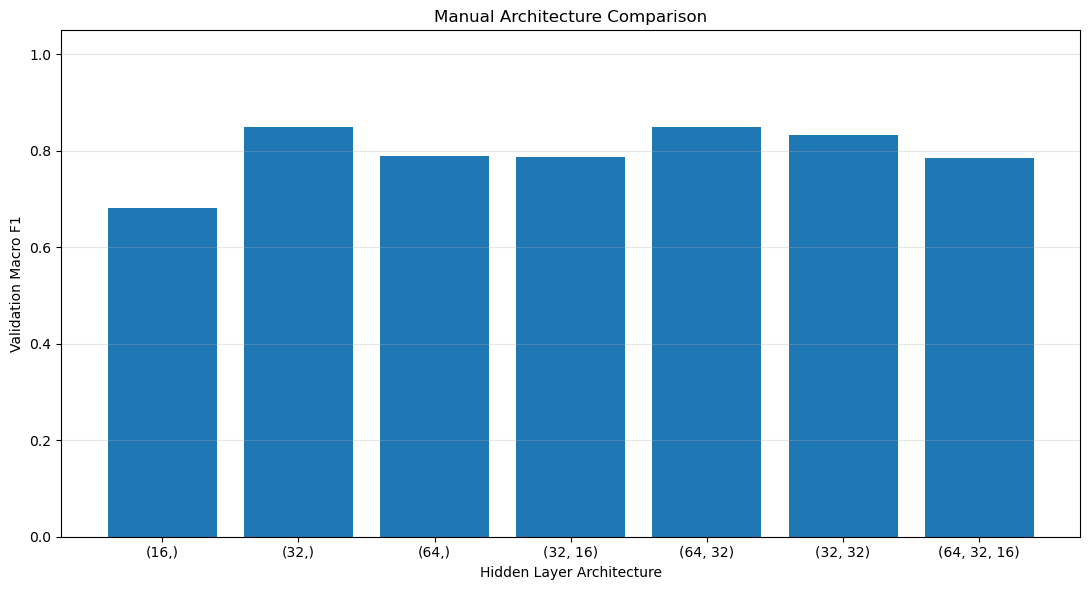

In [19]:
plt.figure(figsize=(11, 6))

labels = systematic_df["Architecture"].tolist()
scores = systematic_df["Macro_F1"].to_numpy()

plt.bar(labels, scores)
plt.xlabel("Hidden Layer Architecture")
plt.ylabel("Validation Macro F1")
plt.title("Manual Architecture Comparison")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

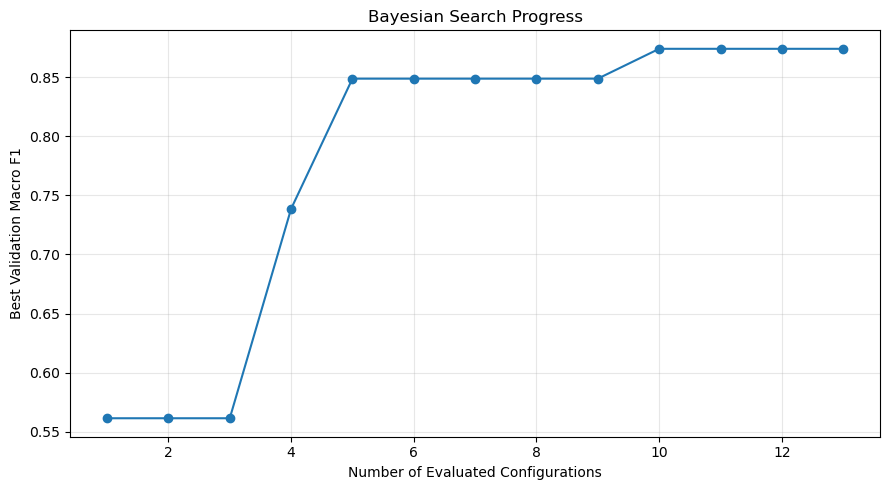

In [20]:
search_scores = np.array(observed_scores)
best_so_far = np.maximum.accumulate(search_scores)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(best_so_far) + 1),
    best_so_far,
    marker="o"
)

plt.xlabel("Number of Evaluated Configurations")
plt.ylabel("Best Validation Macro F1")
plt.title("Bayesian Search Progress")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
X_final_raw = np.vstack([X_train_raw, X_val_raw])
y_final = np.vstack([y_train, y_val])

final_mean, final_std = fit_scaler(X_final_raw)

X_final = transform_data(
    X_final_raw, final_mean, final_std
)

X_test_final = transform_data(
    X_test_raw, final_mean, final_std
)

final_model, final_losses = train_network(
    X_final,
    y_final,
    architecture=best_architecture,
    dropout_rate=best_dropout,
    learning_rate=best_learning_rate,
    epochs=60,
    batch_size=32,
    seed=10
)

test_probabilities, _ = forward(
    X_test_final,
    final_model,
    training=False,
    dropout_rate=0
)

test_metrics = calculate_metrics(
    y_test, test_probabilities
)

print("\nFINAL TEST PERFORMANCE")
for name, value in test_metrics.items():
    print(name, ":", round(value, 4))


FINAL TEST PERFORMANCE
Accuracy : 0.8361
Precision : 0.8286
Recall : 0.8788
F1 : 0.8529
Macro_F1 : 0.8339
Validation_Loss : 0.4101


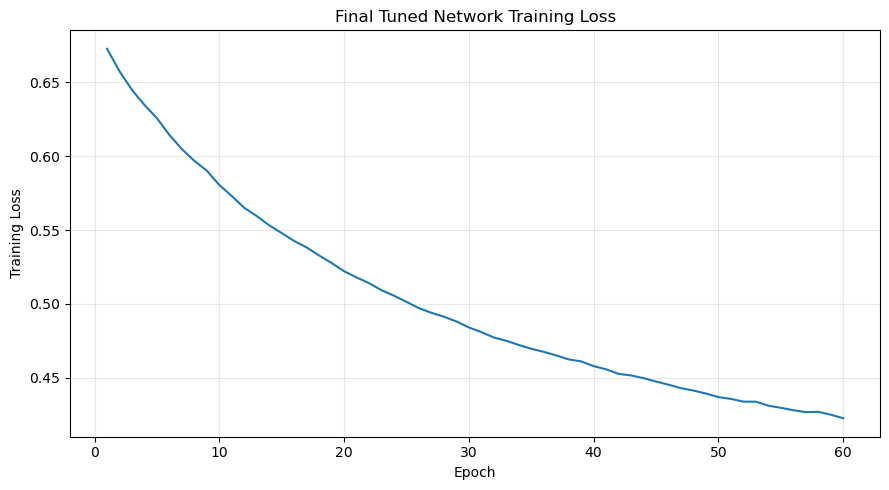


Saved:
manual_architecture_comparison.csv
manual_bayesian_search_results.csv
best_network_test_results.csv


In [22]:
systematic_df.to_csv(
    "manual_architecture_comparison.csv", index=False
)

bayesian_df.to_csv(
    "manual_bayesian_search_results.csv", index=False
)

pd.DataFrame([{
    "Architecture": str(best_architecture),
    "Layers": len(best_architecture),
    "Neurons": sum(best_architecture),
    "Dropout": best_dropout,
    "Learning_Rate": best_learning_rate,
    **test_metrics
}]).to_csv(
    "best_network_test_results.csv", index=False
)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(final_losses) + 1), final_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Final Tuned Network Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSaved:")
print("manual_architecture_comparison.csv")
print("manual_bayesian_search_results.csv")
print("best_network_test_results.csv")